RFM Segmentation & BigQuery ML.

In [1]:
from google.colab import auth
auth.authenticate_user()
print("Authenticated.")

from google.cloud import bigquery
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'

PROJECT_ID = 'cloudiq-analytics'
DATASET    = 'bigquery-public-data.thelook_ecommerce'
MY_DATASET = f'{PROJECT_ID}.cloudiq'   # we will create this in Cell 2

client    = bigquery.Client(project=PROJECT_ID)
FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)

def run_query(sql):
    return client.query(sql).to_dataframe()

print("Client ready.")


Authenticated.
Client ready.


Create dataset in BigQuery (one-time setup)

In [2]:
# BigQuery ML models must live in YOUR project, not the public dataset.
# This creates a dataset called 'cloudiq' inside cloudiq-analytics.

dataset_ref = bigquery.Dataset(MY_DATASET)
dataset_ref.location = 'US'
client.create_dataset(dataset_ref, exists_ok=True)
print(f"Dataset ready: {MY_DATASET}")


Dataset ready: cloudiq-analytics.cloudiq


RFM: build scores in BigQuery SQL

In [3]:
print("=" * 65)
print("SECTION 1: RFM CUSTOMER SEGMENTATION")
print("=" * 65)
print("""
RFM is a simple, powerful framework for segmenting customers:

  Recency   — how recently did they last buy?      (lower days = better)
  Frequency — how many orders have they placed?    (higher = better)
  Monetary  — how much have they spent in total?   (higher = better)

We score each dimension 1–5 using NTILE(5) — a BigQuery window function
that splits customers into five equal-sized buckets. Score 5 is best.

Combined RFM score (e.g. 555) maps to named segments:
  Champions      → 555, 554, 545, 544, 455, 454, 445
  Loyal          → 543, 444, 435, 355, 354, 345, 344, 335
  Potential      → 553, 551, 552, 541, 542, 533, 532, 531, 452, 451...
  At Risk        → 255, 254, 245, 244, 253, 252, 243, 242
  Cant Lose Them → 155, 154, 144, 214, 215, 115, 114, 113
  Lost           → 111, 112, 121, 131, 141, 151
""")

rfm_sql = f"""
WITH last_order_date AS (
    SELECT MAX(DATE(created_at)) AS max_date
    FROM `{DATASET}.orders`
    WHERE status NOT IN ('Cancelled')
),
customer_rfm AS (
    SELECT
        o.user_id,
        DATE_DIFF(
            (SELECT max_date FROM last_order_date),
            DATE(MAX(o.created_at)),
            DAY
        )                                          AS recency_days,
        COUNT(DISTINCT o.order_id)                 AS frequency,
        ROUND(SUM(oi.sale_price), 2)               AS monetary
    FROM `{DATASET}.orders` o
    JOIN `{DATASET}.order_items` oi ON o.order_id = oi.order_id
    WHERE o.status NOT IN ('Cancelled')
    GROUP BY o.user_id
),
rfm_scores AS (
    SELECT
        user_id,
        recency_days,
        frequency,
        monetary,
        -- Recency: lower days = higher score, so reverse NTILE
        6 - NTILE(5) OVER (ORDER BY recency_days DESC) AS r_score,
        NTILE(5) OVER (ORDER BY frequency ASC)          AS f_score,
        NTILE(5) OVER (ORDER BY monetary ASC)           AS m_score
    FROM customer_rfm
)
SELECT
    *,
    CONCAT(CAST(r_score AS STRING),
           CAST(f_score AS STRING),
           CAST(m_score AS STRING))                AS rfm_score,
    r_score + f_score + m_score                    AS rfm_total
FROM rfm_scores
"""

rfm_df = run_query(rfm_sql)
print(f"RFM scores computed for {len(rfm_df):,} customers")
print()
print(rfm_df[['user_id','recency_days','frequency','monetary',
              'r_score','f_score','m_score','rfm_score','rfm_total']].head(10).to_string(index=False))


SECTION 1: RFM CUSTOMER SEGMENTATION

RFM is a simple, powerful framework for segmenting customers:

  Recency   — how recently did they last buy?      (lower days = better)
  Frequency — how many orders have they placed?    (higher = better)
  Monetary  — how much have they spent in total?   (higher = better)

We score each dimension 1–5 using NTILE(5) — a BigQuery window function
that splits customers into five equal-sized buckets. Score 5 is best.

Combined RFM score (e.g. 555) maps to named segments:
  Champions      → 555, 554, 545, 544, 455, 454, 445
  Loyal          → 543, 444, 435, 355, 354, 345, 344, 335
  Potential      → 553, 551, 552, 541, 542, 533, 532, 531, 452, 451...
  At Risk        → 255, 254, 245, 244, 253, 252, 243, 242
  Cant Lose Them → 155, 154, 144, 214, 215, 115, 114, 113
  Lost           → 111, 112, 121, 131, 141, 151

RFM scores computed for 71,786 customers

 user_id  recency_days  frequency  monetary  r_score  f_score  m_score rfm_score  rfm_total
     268 

Assign segment names

In [4]:
def assign_segment(row):
    r, f, m = row['r_score'], row['f_score'], row['m_score']
    total   = r + f + m

    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3 and m >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'Recent Customers'
    elif r >= 3 and f >= 2 and m >= 2:
        return 'Potential Loyalists'
    elif r == 3 and f <= 2 and m <= 2:
        return 'Promising'
    elif r <= 2 and f >= 3 and m >= 3:
        return 'At Risk'
    elif r == 2 and f >= 4 and m >= 4:
        return "Can't Lose Them"
    elif r <= 2 and f <= 2 and m >= 3:
        return 'Hibernating'
    elif total <= 5:
        return 'Lost'
    else:
        return 'Needs Attention'

rfm_df['segment'] = rfm_df.apply(assign_segment, axis=1)

seg_summary = rfm_df.groupby('segment').agg(
    customers=('user_id', 'count'),
    avg_recency=('recency_days', 'mean'),
    avg_frequency=('frequency', 'mean'),
    avg_monetary=('monetary', 'mean'),
    total_revenue=('monetary', 'sum'),
).round(2).sort_values('total_revenue', ascending=False).reset_index()

seg_summary['customer_share_pct'] = (seg_summary['customers'] / seg_summary['customers'].sum() * 100).round(1)
seg_summary['revenue_share_pct']  = (seg_summary['total_revenue'] / seg_summary['total_revenue'].sum() * 100).round(1)

print("Segment Summary:")
print(seg_summary.to_string(index=False))


Segment Summary:
            segment  customers  avg_recency  avg_frequency  avg_monetary  total_revenue  customer_share_pct  revenue_share_pct
            At Risk      15610       122.76           2.11        209.84     3275528.29                21.7               35.8
   Recent Customers      22191       1238.9            1.0         87.80     1948302.77                30.9               21.3
    Loyal Customers      10057       497.69           1.81        176.68     1776891.11                14.0               19.4
          Champions       4376      1015.83           2.36        254.05     1111722.91                 6.1               12.2
        Hibernating       2924        26.51            1.0        153.89      449971.28                 4.1                4.9
    Needs Attention       8981       250.11           1.16         31.19      280105.75                12.5                3.1
Potential Loyalists       3601       536.75           1.32         47.94      172624.72       

Visualise RFM segments

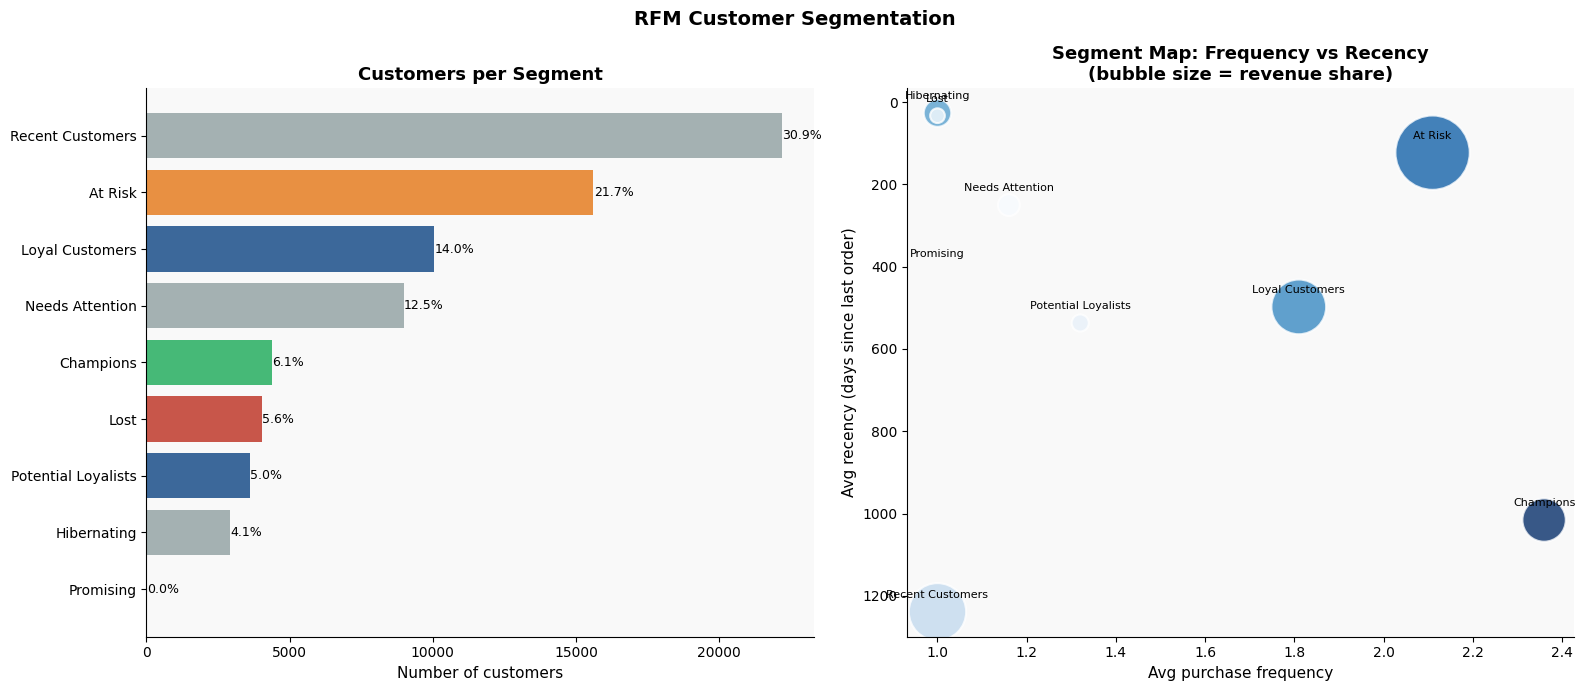

Saved: rfm_scores.csv, rfm_segment_summary.csv


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('RFM Customer Segmentation', fontsize=14, fontweight='bold')

# Customer share by segment
seg_sorted = seg_summary.sort_values('customers', ascending=True)
colors_bar = [GREEN if s == 'Champions'
              else BLUE if s in ('Loyal Customers', 'Potential Loyalists')
              else ORANGE if s in ('At Risk', "Can't Lose Them")
              else RED if s == 'Lost'
              else GREY
              for s in seg_sorted['segment']]

axes[0].barh(seg_sorted['segment'], seg_sorted['customers'],
             color=colors_bar, alpha=0.85)
axes[0].set_title('Customers per Segment', fontweight='bold')
axes[0].set_xlabel('Number of customers')
for i, (_, row) in enumerate(seg_sorted.iterrows()):
    axes[0].text(row['customers'] + 5, i,
                 f"{row['customer_share_pct']}%", va='center', fontsize=9)

# Revenue share bubble chart
axes[1].scatter(
    seg_summary['avg_frequency'],
    seg_summary['avg_recency'],
    s=seg_summary['revenue_share_pct'] * 80,
    c=seg_summary['avg_monetary'],
    cmap='Blues',
    alpha=0.8,
    edgecolors='white',
    linewidth=1.5,
)
for _, row in seg_summary.iterrows():
    axes[1].annotate(
        row['segment'],
        (row['avg_frequency'], row['avg_recency']),
        fontsize=8, ha='center',
        xytext=(0, 10), textcoords='offset points'
    )
axes[1].set_title('Segment Map: Frequency vs Recency\n(bubble size = revenue share)',
                  fontweight='bold')
axes[1].set_xlabel('Avg purchase frequency')
axes[1].set_ylabel('Avg recency (days since last order)')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig(FIGURES / '10_rfm_segments.png', dpi=150, bbox_inches='tight')
plt.show()

rfm_df.to_csv(PROCESSED / 'rfm_scores.csv', index=False)
seg_summary.to_csv(PROCESSED / 'rfm_segment_summary.csv', index=False)
print("Saved: rfm_scores.csv, rfm_segment_summary.csv")


BigQuery ML: build the training dataset

In [6]:
training_sql = f"""
CREATE OR REPLACE TABLE `{MY_DATASET}.repeat_purchase_training` AS

WITH first_orders AS (
    SELECT
        o.user_id,
        MIN(o.order_id)                              AS first_order_id,
        DATE(MIN(o.created_at))                      AS first_order_date,
        ROUND(SUM(oi.sale_price), 2)                 AS first_order_value,
        MAX(p.category)                              AS first_category,
        MAX(o.num_of_item)                           AS num_items
    FROM `{DATASET}.orders` o
    JOIN `{DATASET}.order_items` oi ON o.order_id = oi.order_id
    JOIN `{DATASET}.products` p     ON oi.product_id = p.id
    WHERE o.status NOT IN ('Cancelled')
    GROUP BY o.user_id
),
second_order AS (
    SELECT
        fo.user_id,
        MIN(DATE(o.created_at)) AS second_order_date
    FROM first_orders fo
    JOIN `{DATASET}.orders` o ON fo.user_id = o.user_id
    WHERE o.order_id != fo.first_order_id
      AND o.status NOT IN ('Cancelled')
    GROUP BY fo.user_id
),
traffic AS (
    SELECT
        user_id,
        MAX(traffic_source) AS traffic_source
    FROM `{DATASET}.events`
    GROUP BY user_id
),
combined AS (
    SELECT
        fo.user_id,
        u.age,
        u.gender,
        u.country,
        fo.first_order_value,
        fo.first_category,
        fo.num_items,
        DATE_DIFF(fo.first_order_date, DATE(u.created_at), DAY) AS days_account_to_first_order,
        COALESCE(t.traffic_source, 'Unknown')                    AS traffic_source,
        CASE
            WHEN so.second_order_date IS NOT NULL
             AND DATE_DIFF(so.second_order_date, fo.first_order_date, DAY) <= 90
            THEN 1 ELSE 0
        END AS repeat_buyer
    FROM first_orders fo
    JOIN `{DATASET}.users` u ON fo.user_id = u.id
    LEFT JOIN second_order so ON fo.user_id = so.user_id
    LEFT JOIN traffic t ON fo.user_id = t.user_id
)
SELECT *
FROM combined
WHERE age IS NOT NULL
  AND days_account_to_first_order IS NOT NULL
"""

client.query(training_sql).result()
print(f"Training table created: {MY_DATASET}.repeat_purchase_training")

balance = run_query(f"""
    SELECT repeat_buyer, COUNT(*) AS n,
           ROUND(COUNT(*) / SUM(COUNT(*)) OVER () * 100, 2) AS pct
    FROM `{MY_DATASET}.repeat_purchase_training`
    GROUP BY 1
""")
print()
print("Class balance:")
print(balance.to_string(index=False))


Training table created: cloudiq-analytics.cloudiq.repeat_purchase_training

Class balance:
 repeat_buyer     n   pct
            0 55516 77.34
            1 16270 22.66


Train the BigQuery ML model

In [7]:
train_model_sql = f"""
CREATE OR REPLACE MODEL `{MY_DATASET}.repeat_buyer_model`
OPTIONS(
    model_type        = 'logistic_reg',
    input_label_cols  = ['repeat_buyer'],
    auto_class_weights = TRUE,
    max_iterations    = 20,
    l2_reg            = 0.1
) AS
SELECT
    age,
    gender,
    country,
    first_order_value,
    first_category,
    num_items,
    days_account_to_first_order,
    traffic_source,
    repeat_buyer
FROM `{MY_DATASET}.repeat_purchase_training`
"""

print("Training BigQuery ML logistic regression model...")
print("(This runs entirely inside BigQuery — no data leaves the warehouse)")
print()

import time
start = time.time()
client.query(train_model_sql).result()
elapsed = time.time() - start

print(f"Model trained in {elapsed:.0f} seconds.")
print(f"Model location: {MY_DATASET}.repeat_buyer_model")


Training BigQuery ML logistic regression model...
(This runs entirely inside BigQuery — no data leaves the warehouse)

Model trained in 34 seconds.
Model location: cloudiq-analytics.cloudiq.repeat_buyer_model


Evaluate the model

In [8]:
eval_sql = f"""
SELECT *
FROM ML.EVALUATE(
    MODEL `{MY_DATASET}.repeat_buyer_model`,
    (SELECT age, gender, country, first_order_value, first_category,
            num_items, days_account_to_first_order, traffic_source, repeat_buyer
     FROM `{MY_DATASET}.repeat_purchase_training`)
)
"""
eval_df = run_query(eval_sql)

print("BigQuery ML Model Evaluation:")
print()
for col in eval_df.columns:
    print(f"  {col:<30} : {eval_df[col].values[0]:.4f}")

print()
print("Metric guide:")
print("  precision        : of predicted repeat buyers, how many actually repeated?")
print("  recall           : of actual repeat buyers, how many did we catch?")
print("  accuracy         : overall correct predictions")
print("  f1_score         : harmonic mean of precision and recall")
print("  roc_auc          : discrimination power (0.5 = random, 1.0 = perfect)")
print("  log_loss         : lower is better — penalises confident wrong predictions")

eval_df.to_csv(PROCESSED / 'bqml_evaluation.csv', index=False)


BigQuery ML Model Evaluation:

  precision                      : 0.4697
  recall                         : 0.7242
  accuracy                       : 0.7522
  f1_score                       : 0.5698
  log_loss                       : 0.5196
  roc_auc                        : 0.8162

Metric guide:
  precision        : of predicted repeat buyers, how many actually repeated?
  recall           : of actual repeat buyers, how many did we catch?
  accuracy         : overall correct predictions
  f1_score         : harmonic mean of precision and recall
  roc_auc          : discrimination power (0.5 = random, 1.0 = perfect)
  log_loss         : lower is better — penalises confident wrong predictions


ROC curve

In [9]:
# First: inspect what ML.ROC_CURVE actually returns
roc_cols_sql = f"""
SELECT *
FROM ML.ROC_CURVE(
    MODEL `{MY_DATASET}.repeat_buyer_model`,
    (SELECT age, gender, country, first_order_value, first_category,
            num_items, days_account_to_first_order, traffic_source, repeat_buyer
     FROM `{MY_DATASET}.repeat_purchase_training`)
)
LIMIT 3
"""
roc_sample = run_query(roc_cols_sql)
print("Columns returned by ML.ROC_CURVE:")
print(list(roc_sample.columns))
print()
print(roc_sample)


Columns returned by ML.ROC_CURVE:
['threshold', 'recall', 'false_positive_rate', 'true_positives', 'false_positives', 'true_negatives', 'false_negatives']

   threshold    recall  false_positive_rate  true_positives  false_positives  \
0   0.127442  0.993546             0.834030           16165            46302   
1   0.099498  0.996620             0.884880           16215            49125   
2   0.231746  0.961524             0.649236           15644            36043   

   true_negatives  false_negatives  
0            9214              105  
1            6391               55  
2           19473              626  


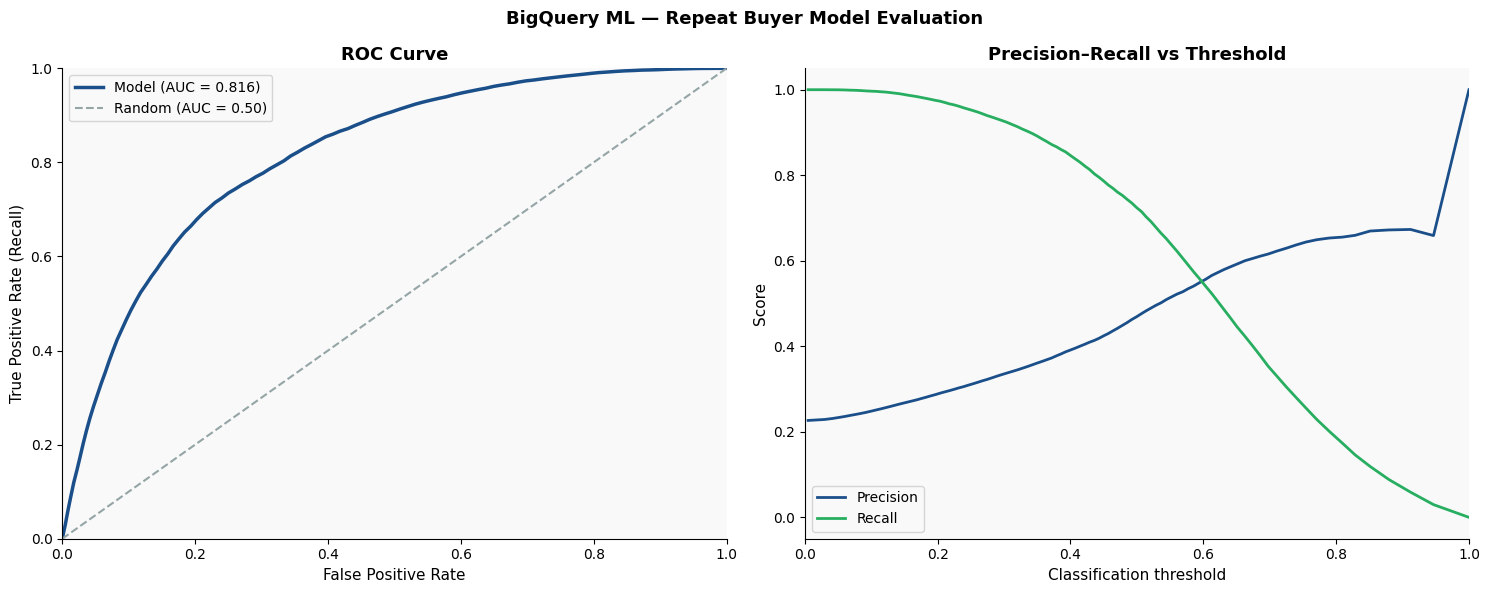

In [10]:
roc_sql = f"""
SELECT
    threshold,
    recall,
    false_positive_rate,
    true_positives,
    false_positives,
    true_negatives,
    false_negatives
FROM ML.ROC_CURVE(
    MODEL `{MY_DATASET}.repeat_buyer_model`,
    (SELECT age, gender, country, first_order_value, first_category,
            num_items, days_account_to_first_order, traffic_source, repeat_buyer
     FROM `{MY_DATASET}.repeat_purchase_training`)
)
ORDER BY threshold
"""
roc_df = run_query(roc_sql)

# Derive precision from confusion matrix columns
roc_df['precision'] = (
    roc_df['true_positives'] /
    (roc_df['true_positives'] + roc_df['false_positives']).replace(0, float('nan'))
)

auc_val = eval_df['roc_auc'].values[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('BigQuery ML — Repeat Buyer Model Evaluation', fontsize=13, fontweight='bold')

axes[0].plot(roc_df['false_positive_rate'], roc_df['recall'],
             color=BLUE, lw=2.5, label=f'Model (AUC = {auc_val:.3f})')
axes[0].plot([0, 1], [0, 1], color=GREY, lw=1.5, linestyle='--', label='Random (AUC = 0.50)')
axes[0].set_title('ROC Curve', fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend()
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)

axes[1].plot(roc_df['threshold'], roc_df['precision'],
             color=BLUE, lw=2, label='Precision')
axes[1].plot(roc_df['threshold'], roc_df['recall'],
             color=GREEN, lw=2, label='Recall')
axes[1].set_title('Precision–Recall vs Threshold', fontweight='bold')
axes[1].set_xlabel('Classification threshold')
axes[1].set_ylabel('Score')
axes[1].legend()
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.savefig(FIGURES / '11_bqml_roc.png', dpi=150, bbox_inches='tight')
plt.show()


Feature importance

In [11]:
# Step 1: inspect columns ML.WEIGHTS returns for this model
weights_sample_sql = f"""
SELECT *
FROM ML.WEIGHTS(MODEL `{MY_DATASET}.repeat_buyer_model`)
LIMIT 3
"""
w_sample = run_query(weights_sample_sql)
print("Columns returned by ML.WEIGHTS:")
print(list(w_sample.columns))
print()
print(w_sample)


Columns returned by ML.WEIGHTS:
['processed_input', 'weight', 'category_weights']

  processed_input    weight                                   category_weights
0             age -0.000163                                                 []
1          gender       NaN  [{'category': 'M', 'weight': -0.20858953811884...
2         country       NaN  [{'category': 'Brasil', 'weight': -0.092278296...


Top 20 features by absolute weight:
                                     feature    weight
                              country=España -2.558666
                  first_category=Accessories -1.577172
            first_category=Blazers & Jackets -1.518706
                      first_category=Dresses -1.413036
                       first_category=Active -1.343402
                      traffic_source=Adwords -1.090021
                first_category=Clothing Sets -1.082406
first_category=Fashion Hoodies & Sweatshirts -1.004114
                             country=Austria -0.752509
                        first_category=Jeans -0.731171
            first_category=Outerwear & Coats -0.709505
                            country=Colombia -0.617634
                    first_category=Underwear  0.579251
                    first_category=Intimates -0.575406
          first_category=Jumpsuits & Rompers -0.511782
                  first_category=Tops & Tees  0.465121
                        first

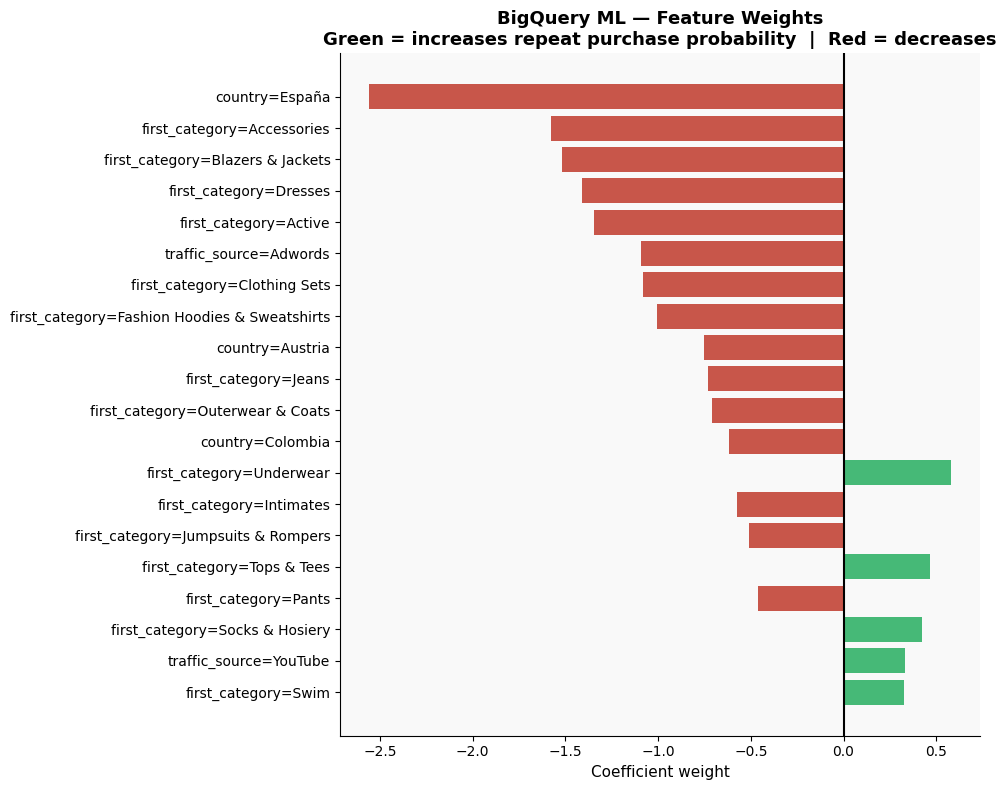

Saved: bqml_feature_weights.csv


In [12]:
weights_sql = f"""
SELECT processed_input, weight, category_weights
FROM ML.WEIGHTS(MODEL `{MY_DATASET}.repeat_buyer_model`)
"""
weights_raw = run_query(weights_sql)

# Extract numeric feature weights
numeric_w = weights_raw[weights_raw['weight'].notna()][['processed_input', 'weight']].copy()
numeric_w.columns = ['feature', 'weight']

# Explode categorical feature weights from nested array of dicts
cat_rows = []
for _, row in weights_raw[weights_raw['weight'].isna()].iterrows():
    for entry in row['category_weights']:
        cat_rows.append({
            'feature': f"{row['processed_input']}={entry['category']}",
            'weight':  entry['weight'],
        })
cat_w = pd.DataFrame(cat_rows) if cat_rows else pd.DataFrame(columns=['feature', 'weight'])

# Combine, sort by absolute weight, take top 20
all_weights = pd.concat([numeric_w, cat_w], ignore_index=True)
all_weights = all_weights.reindex(
    all_weights['weight'].abs().sort_values(ascending=False).index
).head(20).reset_index(drop=True)

print("Top 20 features by absolute weight:")
print(all_weights.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 8))
colors = [GREEN if w > 0 else RED for w in all_weights['weight']]
ax.barh(all_weights['feature'][::-1], all_weights['weight'][::-1],
        color=colors[::-1], alpha=0.85)
ax.axvline(0, color='black', lw=1.5)
ax.set_title('BigQuery ML — Feature Weights\n'
             'Green = increases repeat purchase probability  |  Red = decreases',
             fontweight='bold')
ax.set_xlabel('Coefficient weight')
plt.tight_layout()
plt.savefig(FIGURES / '12_bqml_feature_weights.png', dpi=150, bbox_inches='tight')
plt.show()

all_weights.to_csv(PROCESSED / 'bqml_feature_weights.csv', index=False)
print("Saved: bqml_feature_weights.csv")


Scored 71,786 customers

Top 10 highest repeat-purchase probability:
 user_id  repeat_prob first_category        country  first_order_value
   97126       0.9949    Accessories      Australia              14.99
   13783       0.9945    Accessories  United States              25.00
    5798       0.9941    Accessories          China               9.99
   76220       0.9935    Accessories          China               9.95
   91387       0.9935    Accessories  United States              26.44
   87277       0.9935         Active  United States              23.99
   10847       0.9933    Accessories United Kingdom              12.50
   86567       0.9932    Accessories          China              14.99
   89163       0.9929    Accessories          China               3.29
    8301       0.9927    Accessories         Brasil              12.99


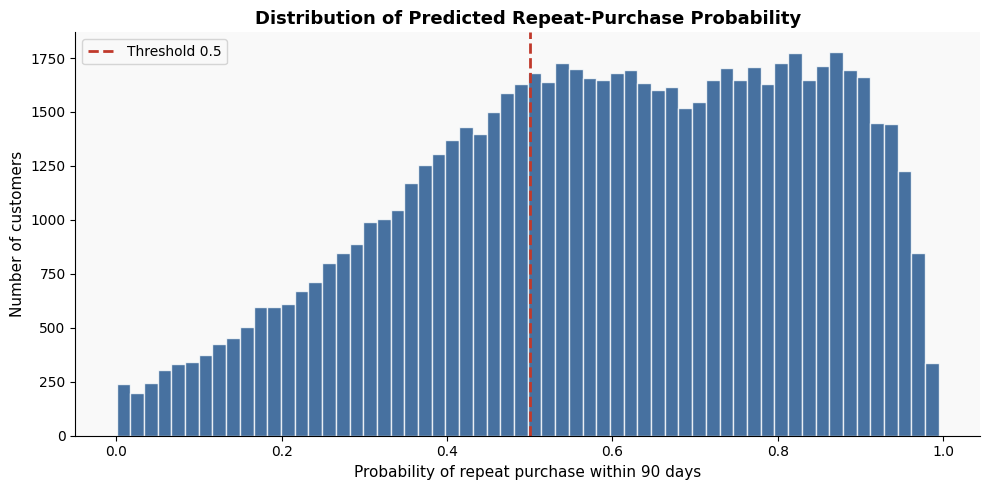

Saved: repeat_purchase_predictions.csv


In [13]:
predict_sql = f"""
SELECT
    p.user_id,
    p.predicted_repeat_buyer,
    ROUND(p.predicted_repeat_buyer_probs[OFFSET(1)].prob, 4) AS repeat_prob,
    t.age, t.gender, t.country, t.first_order_value,
    t.first_category, t.traffic_source
FROM ML.PREDICT(
    MODEL `{MY_DATASET}.repeat_buyer_model`,
    (SELECT * FROM `{MY_DATASET}.repeat_purchase_training`)
) p
JOIN `{MY_DATASET}.repeat_purchase_training` t ON p.user_id = t.user_id
ORDER BY repeat_prob DESC
"""
predictions = run_query(predict_sql)

print(f"Scored {len(predictions):,} customers")
print()
print("Top 10 highest repeat-purchase probability:")
print(predictions[['user_id','repeat_prob','first_category',
                   'country','first_order_value']].head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(predictions['repeat_prob'], bins=60, color=BLUE, alpha=0.8, edgecolor='white', lw=0.3)
ax.set_title('Distribution of Predicted Repeat-Purchase Probability', fontweight='bold')
ax.set_xlabel('Probability of repeat purchase within 90 days')
ax.set_ylabel('Number of customers')
ax.axvline(0.5, color=RED, lw=2, linestyle='--', label='Threshold 0.5')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / '13_repeat_prob_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

predictions.to_csv(PROCESSED / 'repeat_purchase_predictions.csv', index=False)
print("Saved: repeat_purchase_predictions.csv")
